# An in-context mixture of acquisition functions: does a budget- and context-dependent mixture beat every arm?

## Description

<!-- Written 2026-11-13 11:35 before the first run (pre-registration). With Tim, 2026-11-13: solve the convex-hull problem (an in-context mixture of the arms) directly, as the starting point for anything beyond it; sample efficiency counts beside the final regret. Follows notebooks 13 (INCONCLUSIVE) and 15 (NO-GO). Issue #13. -->

**Question.** No single arm is best on every task of the prior. **Is there a policy inside the arms' convex hull, a mixture whose weights depend on the remaining budget and on the context read from the frozen PFN, that beats every single arm on fresh tasks, in final regret and in how fast it gets there? How much of that is the budget, and how much the context?**

Why this and not another value model: notebooks 13 and 15 learned per-state advantages of options from single noisy outcomes; the value models explained 4% of the label variance and the policies collapsed to a static schedule. Here nothing is predicted. Whole policies are compared on whole runs, on the same tasks and candidate sets, and the search follows the paired difference.

**Setup** (`experimental/mixture.py`, `tasks/mixture_policy.py`). Frozen `pfn_large`, fp32, noise-free prior tasks, deterministic candidate sets (512 scrambled Sobol points + 32 perturbations of the incumbent at each of σ = 0.01, 0.05, 0.2; half the size of notebooks 12–15, for speed). Budget T = 20 steps. Two members: **d = 2** (4 initial points) and **d = 4** (8 initial points: the harder problem with a tight budget).
- *Policy.* One PFN pass scores the candidates under EI, PI(0.01), UCB(0.995), MES and the mean. Each arm's scores are normalized within the state: (score − best) / (best − median), so its best candidate is 0 and its median −1. The pick is the argmax of Σₖ wₖ · score_k. With all weight on one arm this is that arm's pick exactly (tested); mixed weights can pick a point that no arm ranks first.
- *Weights.* w = softmax(θ·φ), φ = [1, τ, τ², context features], τ = share of the budget used. 11 context features from the same pass: largest EI and PI, predictive sd near the incumbent and globally, the expected gap to the optimum's value (MES's f\* samples), the incumbent's value, the distance of EI's and UCB's picks to the incumbent, whether EI's pick is a local perturbation, steps since the last improvement, the gap between the two best values. Standardized on states of the uniform mixture. 5 × 14 parameters.
- *Objective* J per task (lower = better): ½ · log10(R_T + ε) + ½ · mean over steps of log10(R_t + ε), with **ε = 1e-3, one PFN bin**. The first half is the final regret, the second the area under the log-regret curve (efficiency). Both are reported separately, also at ε = 1e-4 and 1e-6.
- *Search.* Antithetic perturbations θ ± σe (6 pairs per generation, σ = 0.3), both sides run on the same 128 training tasks (512 in rotation; split 4, offset 80000). Runs are deterministic, so the paired difference is exact; its mean times e is the step direction (Adam). Every 5 generations the current θ is compared with the accepted one on 512 validation tasks (offset 85000) and accepted only if it is better: the accepted policy never gets worse on validation.
  - **Phase 1, budget-only:** only the constant and τ terms. Start: weight 0.83 on the arm that is best on validation.
  - **Phase 2, context:** all terms, starting from phase 1's accepted θ. 50 generations each.
- *Test.* 1536 fresh tasks (offset 90000), under candidate seed 0 (the one trained on) and seed 1 (another candidate set, a luck replicate): every arm, the uniform mixture, the budget-only policy, the context policy.

**What to look for.**
1. **Primary:** the context policy against the best single arm (chosen on validation), on J at ε = 1e-3, seed 0; paired over test tasks, bootstrap CI.
2. The context policy against the budget-only policy: the context-dependent part.
3. The budget-only policy against the best arm: what a learned schedule alone gives.
4. Final regret and area separately, at all three floors; the regret curves; a plot of final regret against area for all policies (is the learned policy on the Pareto front?).
5. Seed 1: does it hold on another candidate set?
6. What was learned: weights along the run, and θ on the context features.
7. d = 4 against d = 2: is the context worth more where the problem is harder?

**GO / NO-GO** (rule `analysis/option_policy.py::policy_verdict` on the context policy, J at ε = 1e-3, seed 0; worthwhile = 0.022 log10).
- **GO**: the context policy beats the best single arm (CI > 0), and beats the budget-only policy (CI > 0, ≥ 0.022). A context-reading policy inside the hull beats the arms and a learned schedule.
- **NO-GO**: the upper CI bound of context over budget-only is < 0.022. The context, read through these features and used linearly, adds nothing to a schedule.
- **INCONCLUSIVE**: otherwise.
- Reported beside the verdict: whether the budget-only policy beats the best arm (CI > 0). That alone is a budget-aware policy that beats every arm, but not the context-dependent one we are after.

**Limits.**
- Inside the convex hull of five arms' normalized scores, linear in 11 hand-made features; not the acquisition branch of decision 0009.
- The floor at 1e-3 makes the objective blind to polishing below one PFN bin, on purpose; the 1e-6 numbers show what that hides.
- The search is small (50 + 50 generations) and local, started at the best arm; a null result bounds this search, not the class.
- Validation tasks are used for acceptance and for choosing the best arm; the test tasks are used once.
- T = 20 at d = 4 is a tight budget chosen to make exploration matter; other budgets are not covered.
- f\* at d = 4 is coarser (notebook 12's addendum); with ε = 1e-3 this does not matter.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.option_policy import policy_verdict
from anytime_acq.analysis.stats import bootstrap_ci

SNAPSHOT = "results/mixture_policy/pilot_20261113-115739"  # set after `just snapshot`
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot

## How it was run

```bash
just sweep detached pilot experiment=mixture_policy task.d=4 task.n_init=8
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261113-115739` |
| commit | `0789f24f4e48` (tag `sweep/mixture_policy/pilot_20261113-115739`) |
| backend / host | detached / ulysses |
| ran | 2026-11-13T11:57:41 → 2026-11-13T15:27:22 |
| members | 1: 1 done |
| compute | 3.5 h wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/mixture_policy.yaml`):

```yaml
# @package _global_
# An in-context mixture of acquisition functions: does a budget- and context-dependent mixture beat every arm?
# (issue #13). Pre-registration: notebooks/17_2026-11-13_mixture_policy.ipynb.
# Members: task.d=2 (n_init 4) and task.d=4 task.n_init=8.
defaults:
  - override /task: mixture_policy

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T: 20
  arms: '["ei", "pi0.01", "ucb0.995", "mes", "mean"]'
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 32
  candidates.n_sobol: 512
  chunk: 256
  d: 4
  device: cuda
  eps: 0.001
  n_boot: 2000
  n_init: 8
  name: mixture_policy
  pfn: pfn_large
  report_eps: '[0.001, 0.0001, 1e-06]'
  search.generations: 50
  search.init_bias: 3.0
  search.lr: 0.15
  search.pairs: 6
  search.sigma: 0.3
  search.val_every: 5
  task_chunk: 128
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  test_tasks.n_tasks: 1536
  test_tasks.split: 4
  test_tasks.task_offset: 90000
  tf32: false
  train_tasks.n_tasks: 512
  train_tasks.split: 4
  train_tasks.task_offset: 80000
  val_tasks.n_tasks: 512
  val_tasks.split: 4
  val_tasks.task_offset: 85000
  w_final: 0.5
  worthwhile_log10: 0.022
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
dmap = dict(zip(runs.member, runs["task.d"])) if "task.d" in runs else {m: int(snap.constants["task.d"]) for m in runs.member}
def tab(name):
    t = snap.table(name)
    return t.assign(d=t.member.map(dmap)) if "member" in t else t.assign(d=list(dmap.values())[0])
train, theta, per, curves, weights, summ = (tab(k) for k in ("train", "theta", "test_per_task", "test_curves", "weights", "summary"))
DS = sorted(per.d.unique()); ARMS = [p for p in per.policy.unique() if p not in ("uniform", "budget", "context")]
display(runs[["member"] + [c for c in runs.columns if c.startswith(("time/", "val_J/", "best_arm"))]].round(3))

member status: {'DONE': 1}


,member,best_arm_index,time/search_s,time/test_s,val_J/ei,val_J/mean,val_J/mes,val_J/pi0.01,val_J/ucb0.995
0,0,3.0,10733.519,1846.726,-2.228,-1.887,-2.253,-2.173,-2.205


## 1. The search

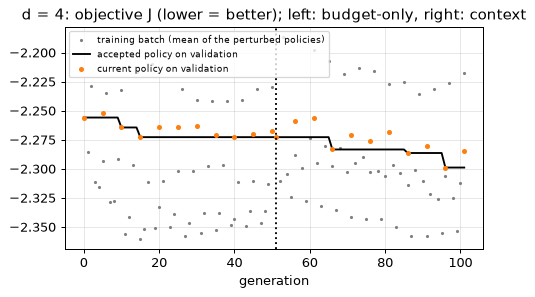

In [ ]:
fig, ax = plt.subplots(1, len(DS), figsize=(6 * len(DS), 3.2), dpi=90, squeeze=False)
for a, d in zip(ax[0], DS):
    g = train[train.d == d].reset_index(drop=True)
    a.plot(g.index, g.J_train, ".", ms=3, color="gray", label="training batch (mean of the perturbed policies)")
    a.plot(g.index, g.J_accepted, "k-", label="accepted policy on validation")
    v = g.dropna(subset=["J_val"]); a.plot(v.index, v.J_val, "o", ms=3, color="C1", label="current policy on validation")
    a.axvline(len(g[g.phase == "budget"]), color="k", ls=":"); a.set_title(f"d = {d}: objective J (lower = better); left: budget-only, right: context")
    a.set_xlabel("generation"); a.grid(alpha=.3); a.legend(fontsize=7)
plt.show()

## 2. Against the arms on fresh tasks

In [ ]:
def show(metric, seed):
    s = summ[(summ.metric == metric) & (summ.seed == seed) & (summ.contrast != "level")]
    return s.assign(ci=[f"{m:+.3f} [{lo:+.3f}, {hi:+.3f}]" for m, lo, hi in zip(s["mean"], s.lo, s.hi)], policy=s.variant.str.split(":").str[0], vs=s.contrast + " (" + s.ref + ")").pivot(index=["d", "policy"], columns="vs", values="ci")
print("objective J at eps = 1e-3 (log10, positive = better than the comparator); paired over test tasks, 95% bootstrap CI")
print("seed 0:"); display(show("J", 0)); print("seed 1 (another candidate set):"); display(show("J", 1))
print("final regret only / area under the curve only (seed 0):"); display(show("final", 0)); display(show("auc", 0))
print("levels of every policy (mean over test tasks, seed 0; lower = better):")
lv = per[per.seed == 0].groupby(["d", "policy"])[[c for c in per.columns if "@" in c]].mean().round(3)
display(lv)

objective J at eps = 1e-3 (log10, positive = better than the comparator); paired over test tasks, 95% bootstrap CI
seed 0:


vs                   vs_base (mes)               vs_ei (ei)  \
d policy                                                      
4 budget   +0.030 [+0.016, +0.045]  +0.042 [+0.026, +0.060]   
  context  +0.037 [+0.023, +0.052]  +0.049 [+0.033, +0.067]   
  uniform  +0.016 [+0.001, +0.031]  +0.028 [+0.014, +0.044]   

vs              vs_static (budget)  
d policy                            
4 budget                       NaN  
  context  +0.007 [-0.007, +0.021]  
  uniform                      NaN

seed 1 (another candidate set):


vs                   vs_base (mes)               vs_ei (ei)  \
d policy                                                      
4 budget   +0.013 [-0.002, +0.027]  +0.030 [+0.013, +0.048]   
  context  +0.011 [-0.005, +0.027]  +0.028 [+0.011, +0.046]   
  uniform  +0.014 [-0.001, +0.029]  +0.031 [+0.016, +0.046]   

vs              vs_static (budget)  
d policy                            
4 budget                       NaN  
  context  -0.002 [-0.018, +0.013]  
  uniform                      NaN

final regret only / area under the curve only (seed 0):


vs                   vs_base (mes)               vs_ei (ei)  \
d policy                                                      
4 budget   +0.020 [+0.001, +0.039]  +0.069 [+0.049, +0.091]   
  context  +0.034 [+0.015, +0.053]  +0.083 [+0.062, +0.105]   
  uniform  -0.002 [-0.022, +0.019]  +0.048 [+0.029, +0.067]   

vs              vs_static (budget)  
d policy                            
4 budget                       NaN  
  context  +0.014 [-0.004, +0.032]  
  uniform                      NaN

vs                   vs_base (mes)               vs_ei (ei)  \
d policy                                                      
4 budget   +0.041 [+0.029, +0.053]  +0.015 [+0.000, +0.030]   
  context  +0.041 [+0.027, +0.055]  +0.016 [+0.000, +0.031]   
  uniform  +0.034 [+0.021, +0.047]  +0.008 [-0.005, +0.022]   

vs              vs_static (budget)  
d policy                            
4 budget                       NaN  
  context  +0.001 [-0.012, +0.012]  
  uniform                      NaN

levels of every policy (mean over test tasks, seed 0; lower = better):


J@0.001  final@0.001  auc@0.001  J@0.0001  final@0.0001  \
d policy                                                              
4 budget     -2.300       -2.460     -2.139    -2.655        -2.892   
  context    -2.307       -2.474     -2.140    -2.663        -2.909   
  ei         -2.258       -2.391     -2.124    -2.591        -2.784   
  mean       -1.911       -1.993     -1.830    -2.116        -2.227   
  mes        -2.270       -2.441     -2.099    -2.609        -2.858   
  pi0.01     -2.201       -2.337     -2.065    -2.469        -2.650   
  ucb0.995   -2.241       -2.426     -2.056    -2.565        -2.834   
  uniform    -2.286       -2.439     -2.133    -2.636        -2.861   

            auc@0.0001  J@1e-06  final@1e-06  auc@1e-06  
d policy                                                 
4 budget        -2.418   -3.023       -3.347     -2.700  
  context       -2.417   -3.025       -3.358     -2.692  
  ei            -2.398   -2.942       -3.204     -2.679  
  mean          -2.005   -2.335       -2.480     -2.190  
  mes           -2.361   -2.972       -3.309     -2.635  
  pi0.01        -2.288   -2.701       -2.921     -2.481  
  ucb0.995      -2.295   -2.906       -3.275     -2.536  
  uniform       -2.410   -2.998       -3.307     -2.690

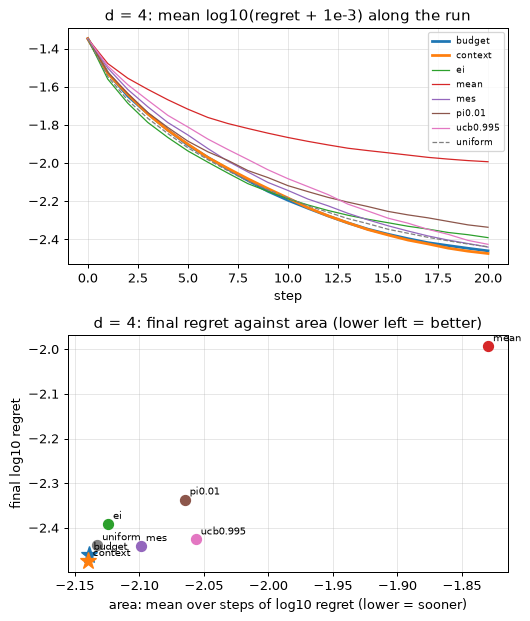

In [ ]:
fig, ax = plt.subplots(2, len(DS), figsize=(6 * len(DS), 7), dpi=90, squeeze=False)
for j, d in enumerate(DS):
    c = curves[(curves.d == d) & (curves.seed == 0) & (curves.eps == 1e-3)]
    for p, g in c.groupby("policy"):
        ax[0, j].plot(g.step, g.log_regret, lw=2.2 if p in ("budget", "context") else 1, ls="--" if p == "uniform" else "-", label=p)
    ax[0, j].set_title(f"d = {d}: mean log10(regret + 1e-3) along the run"); ax[0, j].set_xlabel("step"); ax[0, j].legend(fontsize=7); ax[0, j].grid(alpha=.3)
    m = per[(per.d == d) & (per.seed == 0)].groupby("policy")[["final@0.001", "auc@0.001"]].mean()
    for p, r in m.iterrows():
        ax[1, j].plot(r["auc@0.001"], r["final@0.001"], "o" if p not in ("budget", "context") else "*", ms=8 if p not in ("budget", "context") else 14); ax[1, j].annotate(p, (r["auc@0.001"], r["final@0.001"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax[1, j].set_xlabel("area: mean over steps of log10 regret (lower = sooner)"); ax[1, j].set_ylabel("final log10 regret"); ax[1, j].set_title(f"d = {d}: final regret against area (lower left = better)"); ax[1, j].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 3. What was learned: weights along the run, and the context terms

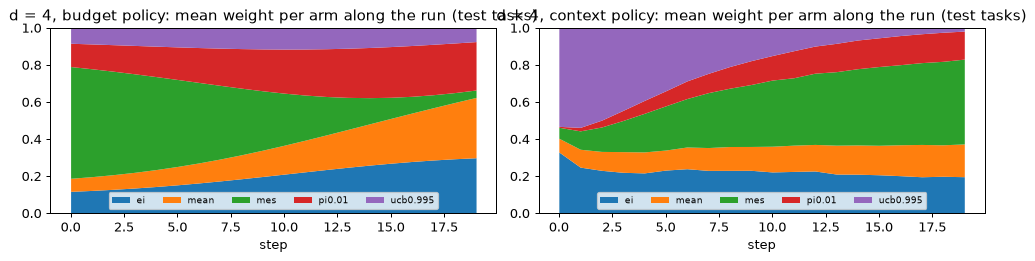

d = 4: theta of the context policy (rows: phi terms; a positive entry moves weight to that arm when the term is high)


arm,ei,mean,mes,pi0.01,ucb0.995
term,,,,,
const,0.64,0.34,2.31,0.85,0.73
ei_pick_dist_inc,0.32,0.12,0.20,-1.73,-1.10
ei_pick_is_local,-1.13,1.22,1.36,-0.68,-0.62
log_expected_fstar_gap,-0.10,-0.45,-0.82,-0.59,1.72
log_gap_best_second,0.78,1.52,-1.05,-0.87,1.54
log_max_ei,0.84,0.54,-0.14,-0.23,1.53
max_pi,1.36,-1.64,0.62,-1.06,-0.91
sd_global,-0.88,-1.33,-1.09,-1.94,0.27
sd_local,0.01,0.33,0.38,-0.88,-0.52


In [ ]:
fig, ax = plt.subplots(len(DS), 2, figsize=(11, 3 * len(DS)), dpi=90, squeeze=False)
for i, d in enumerate(DS):
    for a, p in zip(ax[i], ("budget", "context")):
        weights[(weights.d == d) & (weights.policy == p)].pivot(index="step", columns="arm", values="weight").plot.area(ax=a, lw=0)
        a.set_title(f"d = {d}, {p} policy: mean weight per arm along the run (test tasks)"); a.set_ylim(0, 1); a.legend(fontsize=7, ncol=5, loc="lower center")
plt.tight_layout(); plt.show()
for d in DS:
    print(f"d = {d}: theta of the context policy (rows: phi terms; a positive entry moves weight to that arm when the term is high)")
    display(theta[(theta.d == d) & (theta.policy == "context")].pivot(index="term", columns="arm", values="theta").round(2))

## Observations (d = 4 member, `results/mixture_policy/pilot_20261113-115739`; 2026-11-13)

All numbers are differences of log10(regret + 1e-3), positive = better, paired over 1536 fresh tasks, 95% bootstrap CI, from the `summary` table. The d = 2 member is a separate sweep and is added to the log when it arrives.

1. **Context adds nothing measurable over the budget-only mixture.** Context over budget-only: +0.007 [−0.007, 0.021] in J on seed 0, −0.002 [−0.018, 0.013] on the other candidate set. By the pre-registered rule this is NO-GO (upper bound below 0.022).
2. **The budget-only mixture beats the best arm (MES), by little.** +0.030 [0.016, 0.045] in J on seed 0; on the other candidate set +0.013 [−0.002, 0.027]. About 3–7% less regret.
3. **Most of that is mixing at all, not the learned schedule.** The uniform mixture, never trained, is +0.016 [0.001, 0.031] over MES on seed 0 and +0.014 [−0.001, 0.029] on seed 1. On seed 1 the trained policies are not better than it.
4. **What the mixture buys is both ends at once.** EI has the best area among the arms (−2.124) and a poor final regret (−2.391); MES the best final (−2.441) and a worse area (−2.099). The mixtures have area −2.14 and final −2.46 to −2.47: at or beyond the best arm on each axis (figure in section 2). Against EI the final regret improves by +0.069 [0.049, 0.091] (budget) and +0.083 [0.062, 0.105] (context); against MES the area by +0.041 [0.029, 0.053].
5. **The search moved, slowly.** Validation J went from −2.256 (start) to −2.273 (budget) to −2.299 (context); on the test tasks the context policy's extra 0.026 on validation shrinks to +0.007. With 512 validation tasks the acceptance step itself selects on noise of about this size.
6. **The learned weights differ a lot between the two policies, the outcomes do not.** Budget-only goes from MES early to EI, PI and the mean late; the context policy starts with UCB and moves to MES. The objective is flat across such mixtures.
7. **The floor does not change the picture.** At ε = 1e-4 and 1e-6 the ordering is the same (levels table): mixtures first, then MES, EI, UCB.

Limits: one search seed; 3 h of search under a shared GPU for 100 generations of 6 antithetic pairs on 128 tasks each; T = 20 only; the arms' spread in J is 0.07 (PI to MES) excluding the mean, so the hull is small to begin with.


## Verdict

**d = 4: NO-GO** for the context-dependent mixture by the pre-registered rule (context over budget-only +0.007 [−0.007, 0.021], upper bound below 0.022). The budget-only mixture is a small, real gain over the best arm on the trained candidate set (+0.030 [0.016, 0.045]) that halves on another candidate set. Record with `just decide` once the d = 2 member is in.


In [ ]:
for d in DS:
    s = summ[(summ.d == d) & (summ.metric == "J")]
    b = s[(s.variant == "budget") & (s.seed == 0) & (s.contrast == "vs_base")].iloc[0]
    print(f"d = {d}: pre-registered rule on the context policy: {policy_verdict(s, 'context', 0.022)};"
          f" budget-only over the best arm ({b.ref}): {b['mean']:+.3f} [{b.lo:+.3f}, {b.hi:+.3f}]")

d = 4: pre-registered rule on the context policy: NO-GO; budget-only over the best arm (mes): +0.030 [+0.016, +0.045]
